# Tarea 7 | SVC + Optimización de hiperparámetros + XAI

Telco Customer Churn. Particiones estratificadas 60/20/20; CV de tres folds en entrenamiento; test reservado para el modelo final.

In [23]:

import pickle
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_score,
    train_test_split
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


import pygad


SEED = 42
N_JOBS = 1

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

sns.set_theme(style="whitegrid")


## 1. Datos y exploración

In [24]:
# Lectura del dataset Telco Customer Churn

DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "No se encontró el dataset. Revisa DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset:", DATA_PATH.name)
print("Número de filas:", len(df))
print("Número de columnas:", len(df.columns))

Dataset: WA_Fn-UseC_-Telco-Customer-Churn.csv
Número de filas: 7043
Número de columnas: 21


### Exploracion de datos

In [25]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [26]:
# Dimensiones del dataset
print("Length of the data set:", len(df))
print("Number of characteristics:", len(df.columns))

Length of the data set: 7043
Number of characteristics: 21


In [27]:
# Informacion de las Columnas
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [28]:
# Estadisticas descriptivas
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### Analisis de Datos faltantes

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Distribución porcentual:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


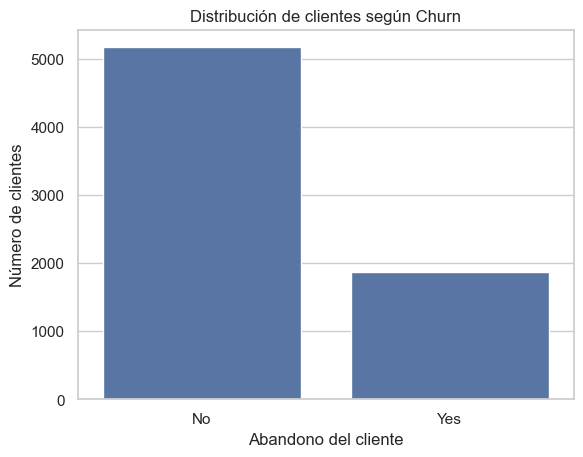

In [29]:
# Distribución de la variable objetivo

print(df["Churn"].value_counts())

print("\nDistribución porcentual:")
print(df["Churn"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="Churn")
plt.title("Distribución de clientes según Churn")
plt.xlabel("Abandono del cliente")
plt.ylabel("Número de clientes")
plt.show()


In [30]:
# Convertir TotalCharges a tipo numerico
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Eliminar customerID
df.drop(["customerID"], axis=1, inplace=True)

# Convertir SeniorCitizen a variable categorica
df["SeniorCitizen"] = df["SeniorCitizen"].astype(str)

# Convertir Churn a valores numericos
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Revisar valores faltantes
print(df.isnull().sum())

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


## 2. Particiones 60/20/20

In [31]:
# Funcion para dividir los datos
def train_val_test_split(df, rstate=42, shuffle=True, stratify=None):
    strat = df[stratify] if stratify else None

    train_set, test_set = train_test_split(
        df,
        test_size=0.4,
        random_state=rstate,
        shuffle=shuffle,
        stratify=strat
    )

    strat = test_set[stratify] if stratify else None

    val_set, test_set = train_test_split(
        test_set,
        test_size=0.5,
        random_state=rstate,
        shuffle=shuffle,
        stratify=strat
    )

    return (train_set, val_set, test_set)


# Funcion para separar caracteristicas y etiquetas
def remove_labels(df, label_name):
    X = df.drop(label_name, axis=1)
    y = df[label_name].copy()

    return (X, y)

In [32]:
# Division estratificada
train_set, val_set, test_set = train_val_test_split(
    df, stratify="Churn"
)

print("Training Set:", len(train_set))
print("Validation Set:", len(val_set))
print("Test Set:", len(test_set))

Training Set: 4225
Validation Set: 1409
Test Set: 1409


In [33]:
# Separacion de caracteristicas y etiquetas

X_train, y_train = remove_labels(train_set, "Churn")
X_val, y_val = remove_labels(val_set, "Churn")
X_test, y_test = remove_labels(test_set, "Churn")

## 3. Preprocesamiento

In [34]:
# Identificar columnas numericas y categoricas
num_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

cat_cols = X_train.select_dtypes(
    exclude="number"
).columns.tolist()


# Pipeline para variables numericas
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])


# Pipeline para variables categoricas
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])


# Combinar los pipelines
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
], verbose_feature_names_out=False)


print("Numericas:", num_cols)
print("Categoricas:", cat_cols)

Numericas: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categoricas: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


# 5.Aplicar fit_transform

In [35]:
# Aprender las transformaciones usando entrenamiento
train_array = preprocessor.fit_transform(X_train)

# Obtener nombres de las caracteristicas
feature_names = preprocessor.get_feature_names_out()

# Convertir a DataFrame
X_train_prep = pd.DataFrame(
    train_array,
    columns=feature_names,
    index=X_train.index
)

X_val_prep = pd.DataFrame(
    preprocessor.transform(X_val),
    columns=feature_names,
    index=X_val.index
)

X_test_prep = pd.DataFrame(
    preprocessor.transform(X_test),
    columns=feature_names,
    index=X_test.index
)

X_train_prep.head()

,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,SeniorCitizen_0,SeniorCitizen_1,Partner_No,Partner_Yes,Dependents_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
2833,0.804348,-0.171846,0.764122,1.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0
846,0.782609,0.261426,1.180819,1.0,0.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0
2501,0.934783,-0.917733,-0.005556,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
6729,0.847826,0.043876,1.034589,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0
2903,-0.369565,-0.640768,-0.272078,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [36]:

# Verificar valores faltantes despues del preprocesamiento

print("Valores faltantes en entrenamiento:")
print(X_train_prep.isnull().sum().sum())

print("Valores faltantes en validacion:")
print(X_val_prep.isnull().sum().sum())

print("Valores faltantes en prueba:")
print(X_test_prep.isnull().sum().sum())


Valores faltantes en entrenamiento:
0
Valores faltantes en validacion:
0
Valores faltantes en prueba:
0


## 4. SVC base y algoritmo genético

### Entrenamiento SVC Base

In [37]:
# Modelo base SVC

svc_pipeline = Pipeline([
    ("prep", clone(preprocessor)),
    ("svc", SVC(
        C=1.0,
        kernel="rbf",
        gamma="scale",
        probability=True,
        random_state=SEED
    ))
])

# Entrenar el modelo
start = time.perf_counter()

svc_pipeline.fit(X_train, y_train)

t_base = time.perf_counter() - start

# Realizar predicciones
y_pred = svc_pipeline.predict(X_val)
y_proba = svc_pipeline.predict_proba(X_val)[:, 1]

print("Tiempo de entrenamiento:", round(t_base, 4), "segundos")
print("F1-Score Base:", f1_score(y_val, y_pred))

Tiempo de entrenamiento: 2.8285 segundos
F1-Score Base: 0.5880551301684533


In [38]:
# Metricas del modelo base

accuracy = accuracy_score(y_val, y_pred)
precision = precision_score(y_val, y_pred)
recall = recall_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)
roc_auc = roc_auc_score(y_val, y_proba)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))

Accuracy: 0.8091
Precision: 0.6882
Recall: 0.5134
F1-Score: 0.5881
ROC-AUC: 0.8123


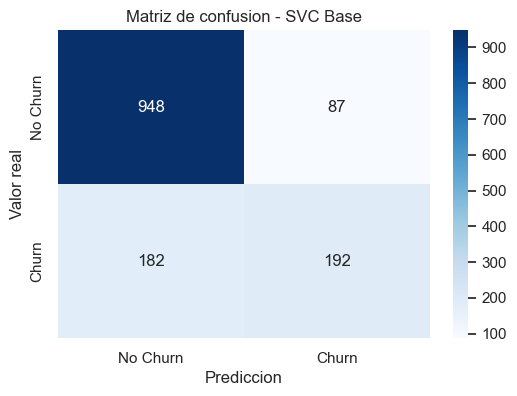

In [39]:
# Matriz de confusion

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Prediccion")
plt.ylabel("Valor real")
plt.title("Matriz de confusion - SVC Base")
plt.show()

### Genético V1

#### Creacion del modelo de optimizacion

In [40]:
# Funcion fitness mejorada

def fitness_func(ga_instance, solution, solution_idx):

    C = 10 ** float(solution[0])
    gamma = 10 ** float(solution[1])

    class_weight = (
        None if int(solution[2]) == 0
        else "balanced"
    )

    model = Pipeline([
        ("prep", clone(preprocessor)),
        ("svc", SVC(
            C=C,
            gamma=gamma,
            kernel="rbf",
            class_weight=class_weight,
            random_state=SEED
        ))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        scoring="f1",
        cv=cv,
        n_jobs=N_JOBS
    )

    return scores.mean()


In [41]:
# Espacio de busqueda de hiperparametros


gene_space = [
    np.linspace(-2, 2, 9),  # C
    np.linspace(-4, 0, 9),  # gamma
    [0, 1]                 # class_weight
]


print("Valores posibles de C:", 10 ** gene_space[0])
print("Valores posibles de gamma:", 10 ** gene_space[1])

Valores posibles de C: [1.00000000e-02 3.16227766e-02 1.00000000e-01 3.16227766e-01
 1.00000000e+00 3.16227766e+00 1.00000000e+01 3.16227766e+01
 1.00000000e+02]
Valores posibles de gamma: [1.00000000e-04 3.16227766e-04 1.00000000e-03 3.16227766e-03
 1.00000000e-02 3.16227766e-02 1.00000000e-01 3.16227766e-01
 1.00000000e+00]


#### Configuracion del algoritmo genetico 

In [42]:
# Configuracion del algoritmo genetico

ga = pygad.GA(
    num_generations=5,
    num_parents_mating=3,
    fitness_func=fitness_func,
    sol_per_pop=6,
    num_genes=len(gene_space),
    gene_space=gene_space,
    mutation_num_genes=1,
    random_seed=SEED
)


In [43]:
# Ejecutar optimizacion genetica
start_ga = time.perf_counter()

ga.run()

end_ga = time.perf_counter()

print("Tiempo de optimizacion:", round(end_ga - start_ga, 2), "segundos")


Tiempo de optimizacion: 50.88 segundos


#### Obtencion de los mejores hyperparametros

In [44]:
# Obtener mejor solucion

best_solution, best_fitness, _ = ga.best_solution()

best_params_ga = {
    "C": 10 ** float(best_solution[0]),
    "gamma": 10 ** float(best_solution[1])
}

print("\n===== RESULTADOS GENETIC OPTIMIZATION =====")

print("Generaciones:", ga.generations_completed)
print("Mejor F1 CV:", round(best_fitness, 4))

print("\nMejores hiperparametros:")
for k, v in best_params_ga.items():
    print(k, ":", v)

print("\nTiempo total:", round(end_ga - start_ga, 2), "segundos")


===== RESULTADOS GENETIC OPTIMIZATION =====
Generaciones: 5
Mejor F1 CV: 0.6225

Mejores hiperparametros:
C : 0.31622776601683794
gamma : 0.31622776601683794

Tiempo total: 50.88 segundos


#### Aplicamos el modelo de optimizacion

In [45]:
# Modelo SVC optimizado con Genetic Algorithm

best_svc_ga = Pipeline([
    ("prep", clone(preprocessor)),
    ("svc", SVC(
        C=best_params_ga["C"],
        gamma=best_params_ga["gamma"],
        kernel="rbf",
        probability=True,
        random_state=SEED
    ))
])

# Entrenar el modelo optimizado
best_svc_ga.fit(X_train, y_train)

,steps,"[('prep', ...), ('svc', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [46]:
# Predicciones del SVC optimizado

y_val_pred_ga = best_svc_ga.predict(X_val)
y_val_proba_ga = best_svc_ga.predict_proba(X_val)[:, 1]

# Metricas del SVC optimizado

acc_val_ga = accuracy_score(y_val, y_val_pred_ga)
precision_val_ga = precision_score(y_val, y_val_pred_ga)
recall_val_ga = recall_score(y_val, y_val_pred_ga)
f1_val_ga = f1_score(y_val, y_val_pred_ga)
auc_val_ga = roc_auc_score(y_val, y_val_proba_ga)

print("\n===== METRICAS SVC GENETIC OPTIMIZATION =====")

print(f"Accuracy: {acc_val_ga:.4f}")
print(f"Precision: {precision_val_ga:.4f}")
print(f"Recall: {recall_val_ga:.4f}")
print(f"F1-Score: {f1_val_ga:.4f}")
print(f"ROC-AUC: {auc_val_ga:.4f}")



===== METRICAS SVC GENETIC OPTIMIZATION =====
Accuracy: 0.8084
Precision: 0.7241
Recall: 0.4492
F1-Score: 0.5545
ROC-AUC: 0.8072


# Comparacion entre  SVC Base vs SVC Genetic optimization

In [47]:
# Comparacion de modelos

comparacion = pd.DataFrame({
    "Metrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "SVC Base": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],
    "SVC Genetico": [
        acc_val_ga,
        precision_val_ga,
        recall_val_ga,
        f1_val_ga,
        auc_val_ga
    ]
})

display(comparacion.round(4))

,Metrica,SVC Base,SVC Genetico
0,Accuracy,0.8091,0.8084
1,Precision,0.6882,0.7241
2,Recall,0.5134,0.4492
3,F1-Score,0.5881,0.5545
4,ROC-AUC,0.8123,0.8072


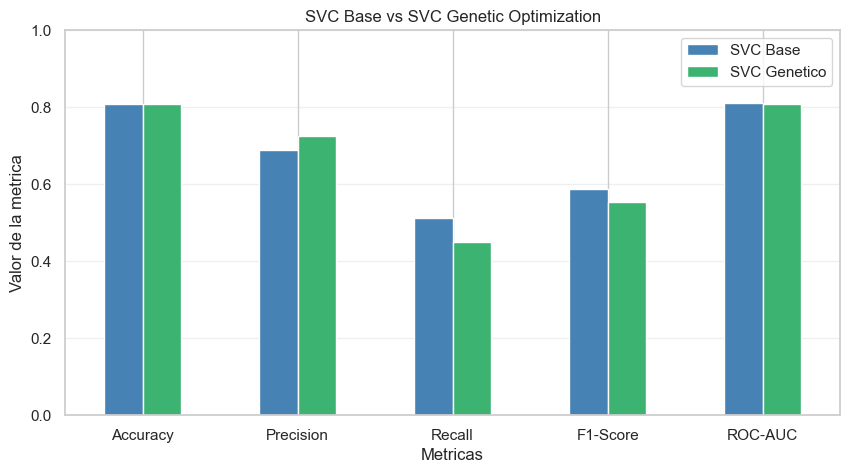

In [48]:
# Grafica comparativa

comparacion.set_index("Metrica").plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "mediumseagreen"]
)

plt.title("SVC Base vs SVC Genetic Optimization")
plt.ylabel("Valor de la metrica")
plt.xlabel("Metricas")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

# 4. Matriz de confusión del SVC optimizado

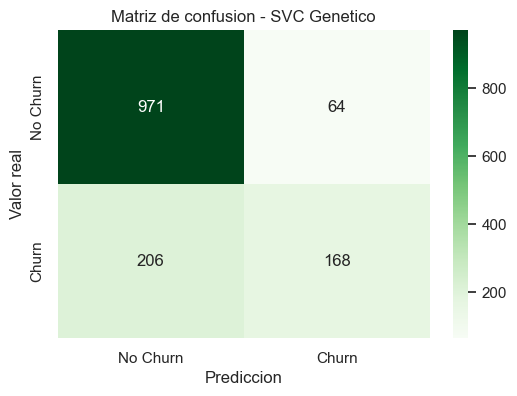

In [49]:
# Matriz de confusion del modelo genetico

cm_ga = confusion_matrix(y_val, y_val_pred_ga)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_ga,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Prediccion")
plt.ylabel("Valor real")
plt.title("Matriz de confusion - SVC Genetico")
plt.show()


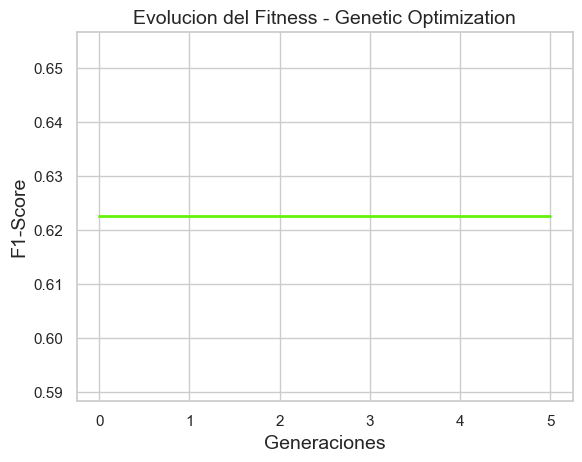

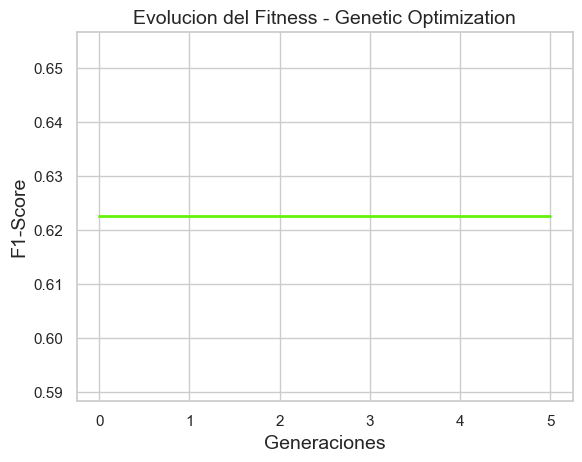

In [50]:
# Evolucion del algoritmo genetico

ga.plot_fitness(
    title="Evolucion del Fitness - Genetic Optimization",
    xlabel="Generaciones",
    ylabel="F1-Score",
    linewidth=2
)


### Genético V2

In [51]:

ga_v2 = pygad.GA(
    num_generations=10,
    num_parents_mating=4,
    fitness_func=fitness_func,
    sol_per_pop=10,
    num_genes=len(gene_space),
    gene_space=gene_space,
    mutation_num_genes=1,
    random_seed=SEED
)

start_ga_v2 = time.perf_counter()

ga_v2.run()

end_ga_v2 = time.perf_counter()

best_solution_v2, best_fitness_v2, _ = ga_v2.best_solution()

best_params_v2 = {
    "C": 10 ** float(best_solution_v2[0]),
    "gamma": 10 ** float(best_solution_v2[1]),
    "class_weight": (
        None if int(best_solution_v2[2]) == 0
        else "balanced"
    )
}

print("===== GENETIC OPTIMIZATION V2 =====")
print("Mejor F1 CV:", round(best_fitness_v2, 4))
print("Mejores hiperparametros:", best_params_v2)
print("Tiempo:", round(end_ga_v2 - start_ga_v2, 2), "segundos")


===== GENETIC OPTIMIZATION V2 =====
Mejor F1 CV: 0.6225
Mejores hiperparametros: {'C': 0.31622776601683794, 'gamma': 0.31622776601683794, 'class_weight': 'balanced'}
Tiempo: 165.36 segundos


In [52]:
# Modelo SVC optimizado V2

best_svc_ga_v2 = Pipeline([
    ("prep", clone(preprocessor)),
    ("svc", SVC(
        C=best_params_v2["C"],
        gamma=best_params_v2["gamma"],
        kernel="rbf",
        class_weight=best_params_v2["class_weight"],
        probability=True,
        random_state=SEED
    ))
])

# Entrenamiento
best_svc_ga_v2.fit(X_train, y_train)

# Predicciones en validacion
y_val_pred_ga_v2 = best_svc_ga_v2.predict(X_val)
y_val_proba_ga_v2 = best_svc_ga_v2.predict_proba(X_val)[:, 1]


In [53]:
# Metricas del modelo genetico V2

acc_val_ga_v2 = accuracy_score(y_val, y_val_pred_ga_v2)
precision_val_ga_v2 = precision_score(y_val, y_val_pred_ga_v2)
recall_val_ga_v2 = recall_score(y_val, y_val_pred_ga_v2)
f1_val_ga_v2 = f1_score(y_val, y_val_pred_ga_v2)
auc_val_ga_v2 = roc_auc_score(y_val, y_val_proba_ga_v2)

print("===== METRICAS SVC GENETICO V2 =====")

print(f"Accuracy: {acc_val_ga_v2:.4f}")
print(f"Precision: {precision_val_ga_v2:.4f}")
print(f"Recall: {recall_val_ga_v2:.4f}")
print(f"F1-Score: {f1_val_ga_v2:.4f}")
print(f"ROC-AUC: {auc_val_ga_v2:.4f}")

===== METRICAS SVC GENETICO V2 =====
Accuracy: 0.7700
Precision: 0.5477
Recall: 0.7674
F1-Score: 0.6392
ROC-AUC: 0.8340


In [54]:
# Tabla comparativa de los tres modelos

comparacion_final = pd.DataFrame({
    "Metrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "SVC Base": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],
    "Genetico V1": [
        acc_val_ga,
        precision_val_ga,
        recall_val_ga,
        f1_val_ga,
        auc_val_ga
    ],
    "Genetico V2": [
        acc_val_ga_v2,
        precision_val_ga_v2,
        recall_val_ga_v2,
        f1_val_ga_v2,
        auc_val_ga_v2
    ]
})

display(comparacion_final.round(4))


,Metrica,SVC Base,Genetico V1,Genetico V2
0,Accuracy,0.8091,0.8084,0.7700
1,Precision,0.6882,0.7241,0.5477
2,Recall,0.5134,0.4492,0.7674
3,F1-Score,0.5881,0.5545,0.6392
4,ROC-AUC,0.8123,0.8072,0.8340


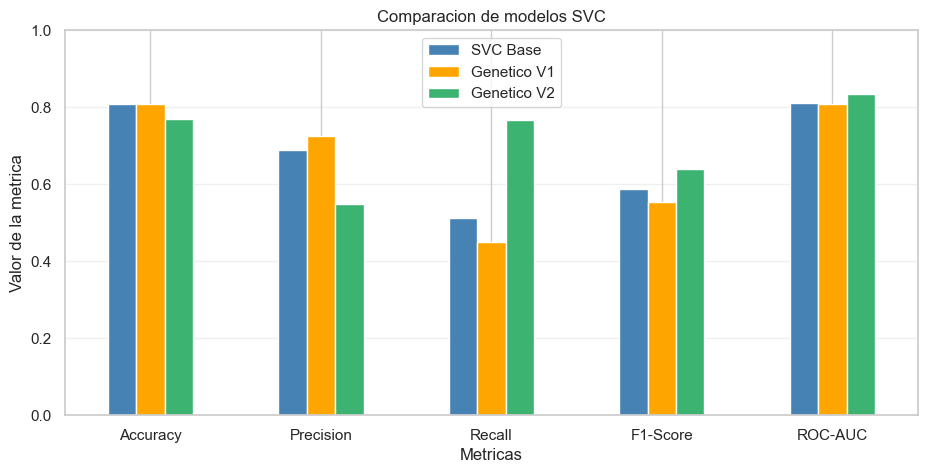

In [55]:
# Comparacion visual

comparacion_final.set_index("Metrica").plot(
    kind="bar",
    figsize=(11, 5),
    color=["steelblue", "orange", "mediumseagreen"]
)

plt.title("Comparacion de modelos SVC")
plt.ylabel("Valor de la metrica")
plt.xlabel("Metricas")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.show()


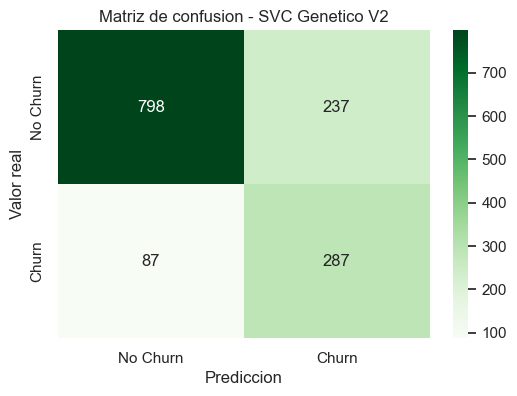

In [56]:
# Matriz de confusion SVC Genetico V2

cm_ga_v2 = confusion_matrix(y_val, y_val_pred_ga_v2)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_ga_v2,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Prediccion")
plt.ylabel("Valor real")
plt.title("Matriz de confusion - SVC Genetico V2")
plt.show()


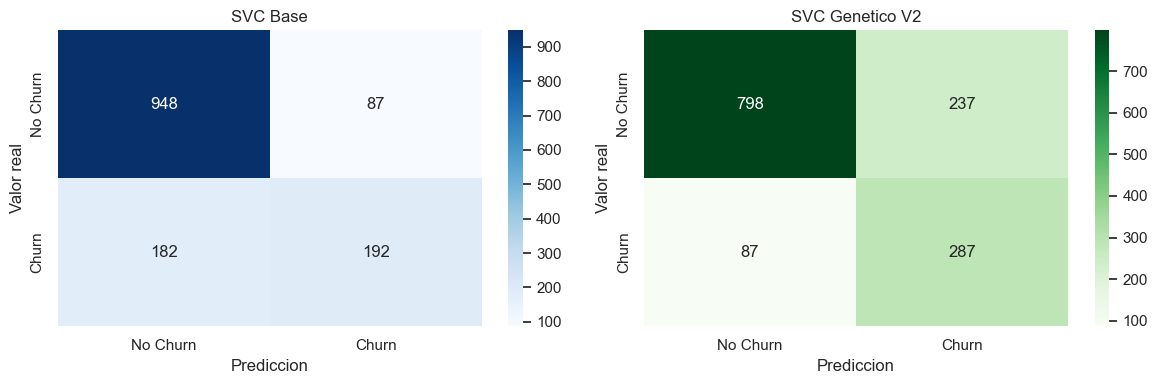

In [57]:
# Comparacion de matrices de confusion

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cm_base = confusion_matrix(y_val, y_pred)
cm_v2 = confusion_matrix(y_val, y_val_pred_ga_v2)

sns.heatmap(
    cm_base,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

axes[0].set_title("SVC Base")
axes[0].set_xlabel("Prediccion")
axes[0].set_ylabel("Valor real")

sns.heatmap(
    cm_v2,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1],
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

axes[1].set_title("SVC Genetico V2")
axes[1].set_xlabel("Prediccion")
axes[1].set_ylabel("Valor real")

plt.tight_layout()
plt.show()


## 5. Comparación adicional de optimización
Mismo SVC RBF, train/validación, CV estratificada de 3 folds. **12 configuraciones** por estrategia nueva. El test sigue reservado. Grid/Random/TPE optimizan F1; NSGA-II optimiza F1 y Recall.

| Método | Espacio | Presupuesto |
|---|---|---|
| Grid | C={0.1,1,10}, gamma={0.01,0.1}, peso={None,balanced} | 12 |
| Random | C y gamma en rejillas logarítmicas, peso categórico | 12 |
| TPE / NSGA-II | C=[0.01,100], gamma=[0.0001,1], peso categórico | 12 cada uno |

Instala en este entorno: python -m pip install optuna. Las cifras solo aparecen al ejecutar las celdas.

In [58]:
from sklearn.model_selection import cross_validate
import optuna

def nuevo_svc(C=1.0, gamma=0.1, peso=None):
    return Pipeline([("prep", clone(preprocessor)),
                     ("svc", SVC(C=C, gamma=gamma, kernel="rbf", class_weight=peso,
                                 probability=True, random_state=SEED))])
def params_trial(t):
    return {"svc__C": t.suggest_float("C", .01, 100, log=True),
            "svc__gamma": t.suggest_float("gamma", .0001, 1, log=True),
            "svc__class_weight": t.suggest_categorical("peso", [None, "balanced"])}
def puntuar_cv(p, multi=False):
    m=nuevo_svc(p["svc__C"],p["svc__gamma"],p["svc__class_weight"])
    if multi:
        r=cross_validate(m,X_train,y_train,cv=cv,scoring={"f1":"f1","recall":"recall"},n_jobs=N_JOBS)
        return float(r["test_f1"].mean()),float(r["test_recall"].mean())
    return float(cross_val_score(m,X_train,y_train,cv=cv,scoring="f1",n_jobs=N_JOBS).mean())
filas_busqueda=[]
def guardar_busqueda(nombre,p,score,segundos,n):
    filas_busqueda.append({"Estrategia":nombre,"CV_F1":score,"Tiempo_s":segundos,
                           "Configuraciones":n,"C":p["svc__C"],"gamma":p["svc__gamma"],
                           "class_weight":str(p["svc__class_weight"])})

### 5.1 Grid y Random Search

In [59]:
rejilla={"svc__C":[.1,1,10],"svc__gamma":[.01,.1],"svc__class_weight":[None,"balanced"]}
inicio=time.perf_counter()
grid=GridSearchCV(nuevo_svc(),rejilla,cv=cv,scoring="f1",n_jobs=N_JOBS).fit(X_train,y_train)
guardar_busqueda("Grid Search",grid.best_params_,grid.best_score_,
                time.perf_counter()-inicio,len(grid.cv_results_["params"]))
distrib={"svc__C":np.logspace(-2,2,9).tolist(),"svc__gamma":np.logspace(-4,0,9).tolist(),
         "svc__class_weight":[None,"balanced"]}
inicio=time.perf_counter()
random_search=RandomizedSearchCV(nuevo_svc(),distrib,n_iter=12,cv=cv,scoring="f1",
                                 random_state=SEED,n_jobs=N_JOBS).fit(X_train,y_train)
guardar_busqueda("Random Search",random_search.best_params_,random_search.best_score_,
                time.perf_counter()-inicio,len(random_search.cv_results_["params"]))
display(pd.DataFrame(filas_busqueda).round(4))

,Estrategia,CV_F1,Tiempo_s,Configuraciones,C,gamma,class_weight
0,Grid Search,0.6185,66.7265,12,0.1,0.1,balanced
1,Random Search,0.6185,67.9502,12,0.1,0.1,balanced


### 5.2 TPE y NSGA-II: F1 y Recall

[I 2026-11-05 23:41:22,557] A new study created in memory with name: no-name-582a1153-8a67-46bd-b3f3-629362c4ba89
[I 2026-11-05 23:41:30,045] Trial 0 finished with value: 0.3204556573172484 and parameters: {'C': 0.31489116479568624, 'gamma': 0.6351221010640696, 'peso': None}. Best is trial 0 with value: 0.3204556573172484.
[I 2026-11-05 23:41:38,745] Trial 1 finished with value: 0.27946115752691236 and parameters: {'C': 0.04207988669606638, 'gamma': 0.0004207053950287938, 'peso': 'balanced'}. Best is trial 0 with value: 0.3204556573172484.
[I 2026-11-05 23:41:43,971] Trial 2 finished with value: 0.6133337482884785 and parameters: {'C': 2.5378155082656657, 'gamma': 0.06796578090758151, 'peso': 'balanced'}. Best is trial 2 with value: 0.6133337482884785.
[I 2026-11-05 23:41:52,547] Trial 3 finished with value: 0.6001716955988874 and parameters: {'C': 21.368329072358772, 'gamma': 0.0007068974950624604, 'peso': 'balanced'}. Best is trial 2 with value: 0.6133337482884785.
[I 2026-11-05 23:4

,F1,Recall,C,gamma,class_weight
0,0.6133,0.7627,2.5378,0.0680,balanced
1,0.6102,0.8225,2.5378,0.0016,balanced
2,0.6054,0.8252,1.2561,0.0053,balanced
3,0.6131,0.8029,0.3149,0.0680,balanced
4,0.6133,0.7627,2.5378,0.0680,balanced
5,0.6102,0.8225,2.5378,0.0016,balanced
6,0.6004,0.8386,0.3149,0.0006,balanced


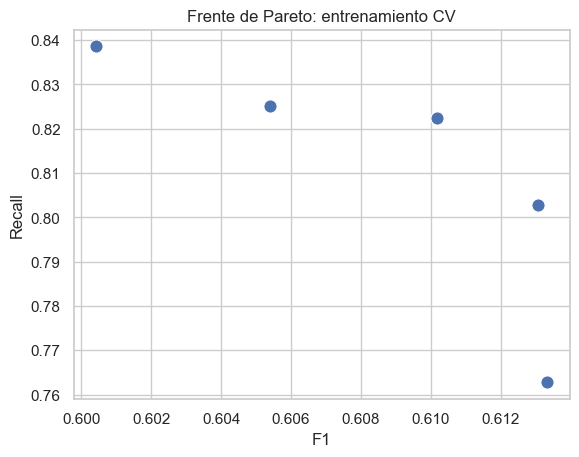

In [60]:
inicio=time.perf_counter()
tpe=optuna.create_study(direction="maximize",sampler=optuna.samplers.TPESampler(seed=SEED))
tpe.optimize(lambda t:puntuar_cv(params_trial(t)),n_trials=12)
pt={"svc__C":tpe.best_params["C"],"svc__gamma":tpe.best_params["gamma"],
    "svc__class_weight":tpe.best_params["peso"]}
guardar_busqueda("TPE",pt,tpe.best_value,time.perf_counter()-inicio,len(tpe.trials))

inicio=time.perf_counter()
nsga=optuna.create_study(directions=["maximize","maximize"],
                         sampler=optuna.samplers.NSGAIISampler(seed=SEED,population_size=4))
nsga.optimize(lambda t:puntuar_cv(params_trial(t),multi=True),n_trials=12)
frente=pd.DataFrame([{"F1":t.values[0],"Recall":t.values[1],"C":t.params["C"],
                      "gamma":t.params["gamma"],"class_weight":str(t.params["peso"])}
                     for t in nsga.best_trials])
display(frente.round(4))
if frente.empty: raise RuntimeError("Sin soluciones de Pareto")
sns.scatterplot(data=frente,x="F1",y="Recall",s=90)
plt.title("Frente de Pareto: entrenamiento CV")
plt.show()
elegido=max(nsga.best_trials,key=lambda t:t.values[0])
pn={"svc__C":elegido.params["C"],"svc__gamma":elegido.params["gamma"],
    "svc__class_weight":elegido.params["peso"]}
guardar_busqueda("NSGA-II",pn,elegido.values[0],time.perf_counter()-inicio,len(nsga.trials))

### 5.3 Comparación final en validación, sin tocar el test

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,SVC Base,0.8091,0.6882,0.5134,0.5881,0.8123
1,Genético V1,0.8084,0.7241,0.4492,0.5545,0.8072
2,Genético V2,0.7700,0.5477,0.7674,0.6392,0.8340
3,Grid Search,0.7275,0.4920,0.8209,0.6152,0.8436
4,Random Search,0.7275,0.4920,0.8209,0.6152,0.8436
5,TPE,0.7544,0.5252,0.7807,0.6280,0.8367
6,NSGA-II,0.7495,0.5185,0.7888,0.6257,0.8343


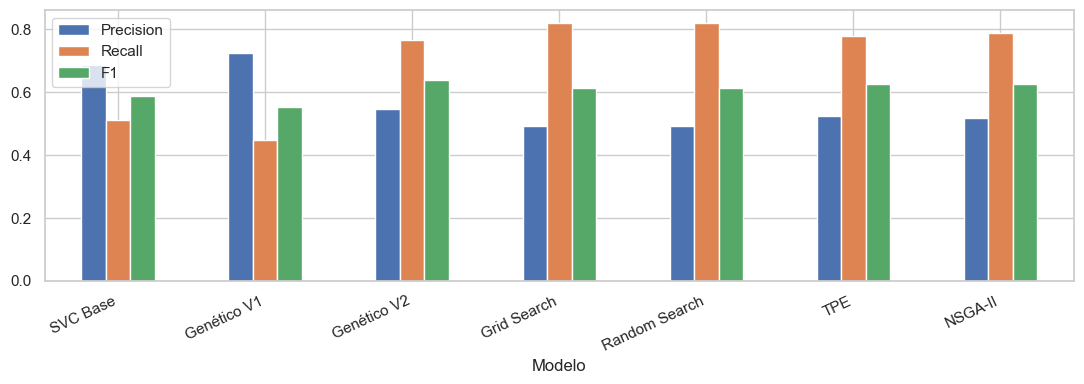

In [61]:
candidatos={"SVC Base":svc_pipeline,"Genético V1":best_svc_ga,
            "Genético V2":best_svc_ga_v2,"Grid Search":grid.best_estimator_,
            "Random Search":random_search.best_estimator_,
            "TPE":nuevo_svc(pt["svc__C"],pt["svc__gamma"],pt["svc__class_weight"]),
            "NSGA-II":nuevo_svc(pn["svc__C"],pn["svc__gamma"],pn["svc__class_weight"])}
filas=[]
for nombre,modelo in candidatos.items():
    if nombre in ("TPE","NSGA-II"):modelo.fit(X_train,y_train)
    pred=modelo.predict(X_val);prob=modelo.predict_proba(X_val)[:,1]
    filas.append({"Modelo":nombre,"Accuracy":accuracy_score(y_val,pred),
                  "Precision":precision_score(y_val,pred,zero_division=0),
                  "Recall":recall_score(y_val,pred,zero_division=0),
                  "F1":f1_score(y_val,pred,zero_division=0),
                  "ROC-AUC":roc_auc_score(y_val,prob)})
metricas_validacion=pd.DataFrame(filas)
display(metricas_validacion.round(4))
metricas_validacion.set_index("Modelo")[["Precision","Recall","F1"]].plot(kind="bar",figsize=(11,4))
plt.xticks(rotation=25,ha="right");plt.tight_layout();plt.show()

## Parte Final


In [62]:
# Unir entrenamiento y validacion

X_train_final = pd.concat([
    X_train,
    X_val
], axis=0)

y_train_final = pd.concat([
    y_train,
    y_val
], axis=0)

print("Entrenamiento final:", len(X_train_final))
print("Prueba:", len(X_test))


Entrenamiento final: 5634
Prueba: 1409


In [63]:
# Modelo final SVC Genetic Optimization

final_model = Pipeline([
    ("prep", clone(preprocessor)),
    ("svc", SVC(
        C=best_params_v2["C"],
        gamma=best_params_v2["gamma"],
        kernel="rbf",
        class_weight=best_params_v2["class_weight"],
        probability=True,
        random_state=SEED
    ))
])

# Entrenamiento final
start_final = time.perf_counter()

final_model.fit(X_train_final, y_train_final)

t_final = time.perf_counter() - start_final

print("Modelo final entrenado correctamente")
print(f"Tiempo de entrenamiento: {t_final:.4f} segundos")


Modelo final entrenado correctamente
Tiempo de entrenamiento: 9.3108 segundos


### Evaluar el modelo con el conjunto de prueba

In [64]:
# Evaluacion final en test

y_test_pred = final_model.predict(X_test)
y_test_proba = final_model.predict_proba(X_test)[:, 1]

# Metricas finales
accuracy_test = accuracy_score(y_test, y_test_pred)
precision_test = precision_score(y_test, y_test_pred)
recall_test = recall_score(y_test, y_test_pred)
f1_test = f1_score(y_test, y_test_pred)
auc_test = roc_auc_score(y_test, y_test_proba)

print("\n===== RESULTADOS FINALES EN TEST =====")

print(f"Accuracy: {accuracy_test:.4f}")
print(f"Precision: {precision_test:.4f}")
print(f"Recall: {recall_test:.4f}")
print(f"F1-Score: {f1_test:.4f}")
print(f"ROC-AUC: {auc_test:.4f}")



===== RESULTADOS FINALES EN TEST =====
Accuracy: 0.7537
Precision: 0.5252
Recall: 0.7513
F1-Score: 0.6183
ROC-AUC: 0.8046


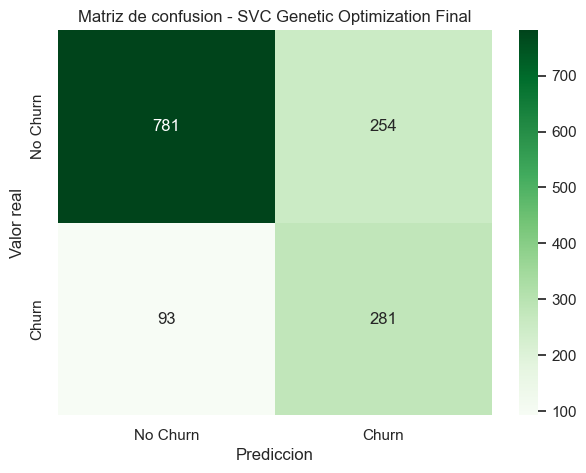

In [65]:
# Matriz de confusion final

cm_final = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Prediccion")
plt.ylabel("Valor real")
plt.title("Matriz de confusion - SVC Genetic Optimization Final")
plt.show()


In [66]:
# Reporte de clasificacion

print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Churn", "Churn"]
))


              precision    recall  f1-score   support

    No Churn       0.89      0.75      0.82      1035
       Churn       0.53      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.75      0.77      1409



### Exportación de métricas a NexoRetain
Archivos generados con los resultados **reales de esta ejecución**.

In [67]:
RESULTADOS=Path("resultados")
RESULTADOS.mkdir(exist_ok=True)
pd.DataFrame(filas_busqueda).to_csv(RESULTADOS/"comparacion_optimizacion.csv",index=False)
frente.to_csv(RESULTADOS/"pareto_front.csv",index=False)
metricas_validacion.to_csv(RESULTADOS/"metricas_validacion.csv",index=False)
pd.DataFrame([{"Modelo":"SVC Genético V2","Accuracy":accuracy_test,"Precision":precision_test,
               "Recall":recall_test,"F1":f1_test,"ROC-AUC":auc_test}]).to_csv(RESULTADOS/"metricas_test.csv",index=False)
pd.DataFrame({"Churn":np.where(np.asarray(y_test)==1,"Yes","No"),
              "P_Abandono":y_test_proba}).to_csv(RESULTADOS/"predicciones_test.csv",index=False)
print("Archivos listos en",RESULTADOS.resolve())

Archivos listos en C:\Users\diasj\OneDrive\Escritorio\machine\Optimizaci-n-de-Machine-Learning-Explainable-AI-y-Business-Pitch\resultados


In [68]:

# Exportar evolucion del Genetic Algorithm V2

import pandas as pd
from pathlib import Path

# Carpeta donde guardaremos los resultados
RESULTADOS = Path("resultados")

RESULTADOS.mkdir(
    parents=True,
    exist_ok=True
)

# Obtener evolucion del fitness
fitness_df = pd.DataFrame({
    "Generacion": range(len(ga_v2.best_solutions_fitness)),
    "F1": ga_v2.best_solutions_fitness
})

# Mostrar resultados
display(fitness_df)

# Guardar archivo CSV
fitness_df.to_csv(
    RESULTADOS / "fitness_ga_v2.csv",
    index=False
)

print("Fitness exportado correctamente")


,Generacion,F1
0,0,0.622453
1,1,0.622453
2,2,0.622453
3,3,0.622453
4,4,0.622453
5,5,0.622453
6,6,0.622453
7,7,0.622453
8,8,0.622453
9,9,0.622453


Fitness exportado correctamente


# Creacion de la Aplicacion (STREAMLIT)

## Guardar nuestro modelo entrenado

In [69]:
import joblib

# Guardar el pipeline completo

joblib.dump(
    final_model,
    "svc_genetic_telco.pkl"
)

print("Modelo guardado correctamente")


Modelo guardado correctamente


In [70]:
modelo = joblib.load("svc_genetic_telco.pkl")

In [71]:
import shap
from lime.lime_tabular import LimeTabularExplainer

In [72]:
# Obtener componentes del modelo final

prep_final = final_model.named_steps["prep"]
svc_final = final_model.named_steps["svc"]

# Transformar los datos con el preprocesador final
feature_names_final = prep_final.get_feature_names_out()

X_train_final_prep = pd.DataFrame(
    prep_final.transform(X_train_final),
    columns=feature_names_final,
    index=X_train_final.index
)

X_test_final_prep = pd.DataFrame(
    prep_final.transform(X_test),
    columns=feature_names_final,
    index=X_test.index
)

print("Caracteristicas:", len(feature_names_final))

X_test_final_prep.head()


Caracteristicas: 46


,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,SeniorCitizen_0,SeniorCitizen_1,Partner_No,Partner_Yes,Dependents_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
2881,0.043478,-0.116835,0.152516,1.0,0.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3994,0.543478,0.573137,1.167976,1.0,0.0,0.0,1.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2663,0.652174,0.713891,1.515418,1.0,0.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3195,-0.434783,0.187672,-0.216101,1.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
5093,0.434783,-0.077277,0.530342,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0


## Explicador SHAP

In [73]:
# Muestra de referencia para SHAP
background = X_train_final_prep.sample(
    n=30,
    random_state=SEED
)

# Funcion que devuelve la probabilidad de Churn
def predict_churn(X):
    return svc_final.predict_proba(X)[:, 1]

# Crear el explicador
explainer = shap.Explainer(
    predict_churn,
    background,
    algorithm="permutation",
    feature_names=feature_names_final
)

print("Explicador SHAP creado correctamente")


Explicador SHAP creado correctamente


In [74]:
# Seleccionar clientes para el analisis
X_shap = X_test_final_prep.sample(
    n=100,
    random_state=SEED
)

# Calcular valores SHAP
shap_values = explainer(
    X_shap,
    max_evals=2 * X_shap.shape[1] + 1
)

print("Valores SHAP calculados correctamente")


c:\Users\diasj\OneDrive\Documentos\INTRODUCCION_A_LA_PROGRAMACION\.venv\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
c:\Users\diasj\OneDrive\Documentos\INTRODUCCION_A_LA_PROGRAMACION\.venv\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
c:\Users\diasj\OneDrive\Documentos\INTRODUCCION_A_LA_PROGRAMACION\.venv\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
c:\Users\diasj\OneDrive\Documentos\INTRODUCCION_A_LA_PROGRAMACION\.venv\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
c:\Users\diasj\OneDrive\Documentos\INTRODUCCION_A_LA_PROGRAMACION\.venv\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning:

Valores SHAP calculados correctamente


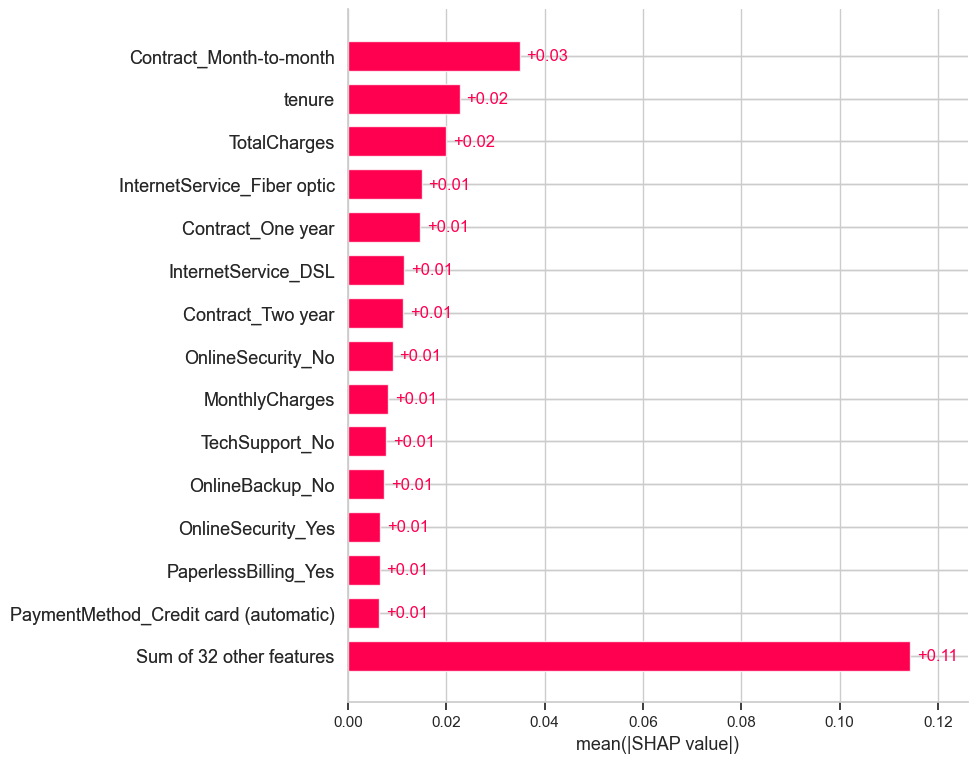

In [75]:
# Importancia global de caracteristicas

shap.plots.bar(
    shap_values,
    max_display=15
)


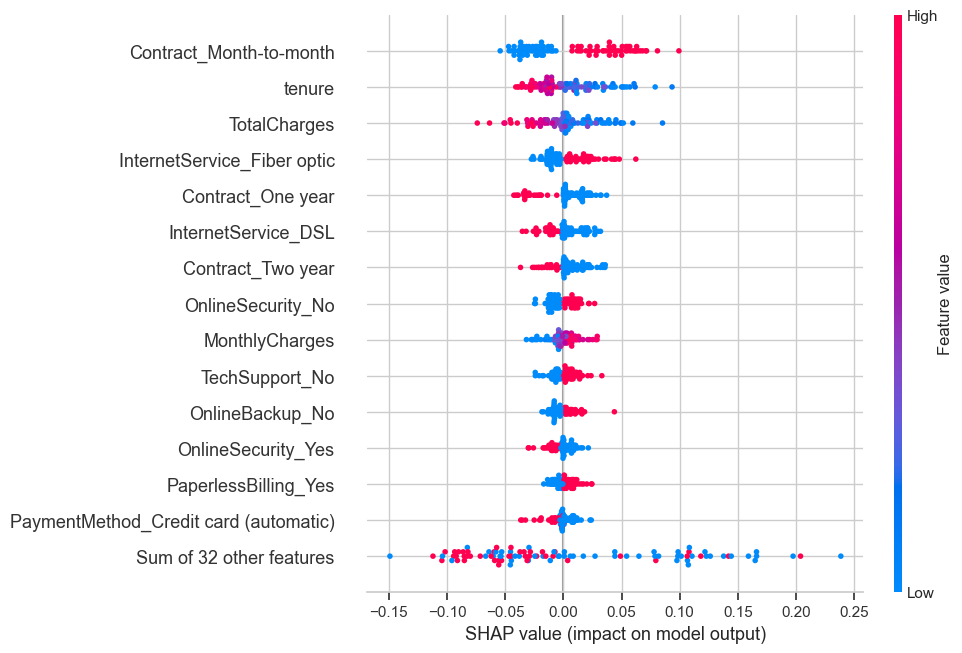

In [76]:
# Distribucion de contribuciones SHAP

shap.plots.beeswarm(
    shap_values,
    max_display=15
)


In [77]:
# Predicciones del modelo final
predicciones = final_model.predict(X_test)

# Posiciones de clientes predichos como Churn y No Churn
clientes_churn = np.where(predicciones == 1)[0]
clientes_no_churn = np.where(predicciones == 0)[0]

# Seleccionar uno de cada clase
idx_churn = clientes_churn[0]
idx_no_churn = clientes_no_churn[0]

indices_clientes = [idx_churn, idx_no_churn]

# Datos de los clientes seleccionados
X_clientes = X_test_final_prep.iloc[indices_clientes]

print("Indices seleccionados:", indices_clientes)
print("Predicciones:", predicciones[indices_clientes])


Indices seleccionados: [np.int64(3), np.int64(0)]
Predicciones: [1 0]


c:\Users\diasj\OneDrive\Documentos\INTRODUCCION_A_LA_PROGRAMACION\.venv\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
c:\Users\diasj\OneDrive\Documentos\INTRODUCCION_A_LA_PROGRAMACION\.venv\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
c:\Users\diasj\OneDrive\Documentos\INTRODUCCION_A_LA_PROGRAMACION\.venv\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


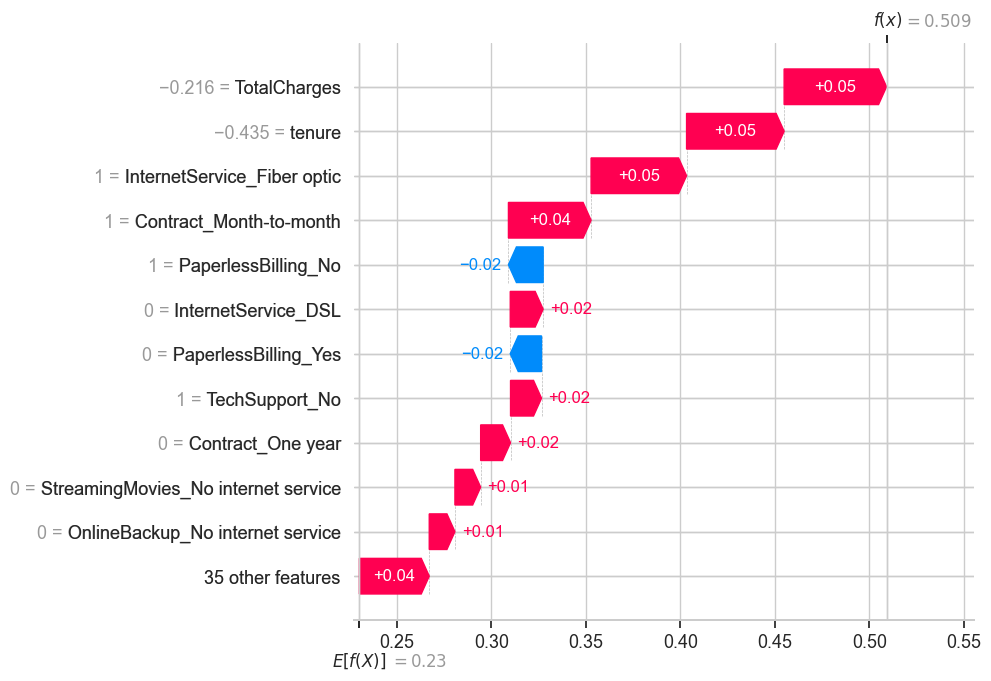

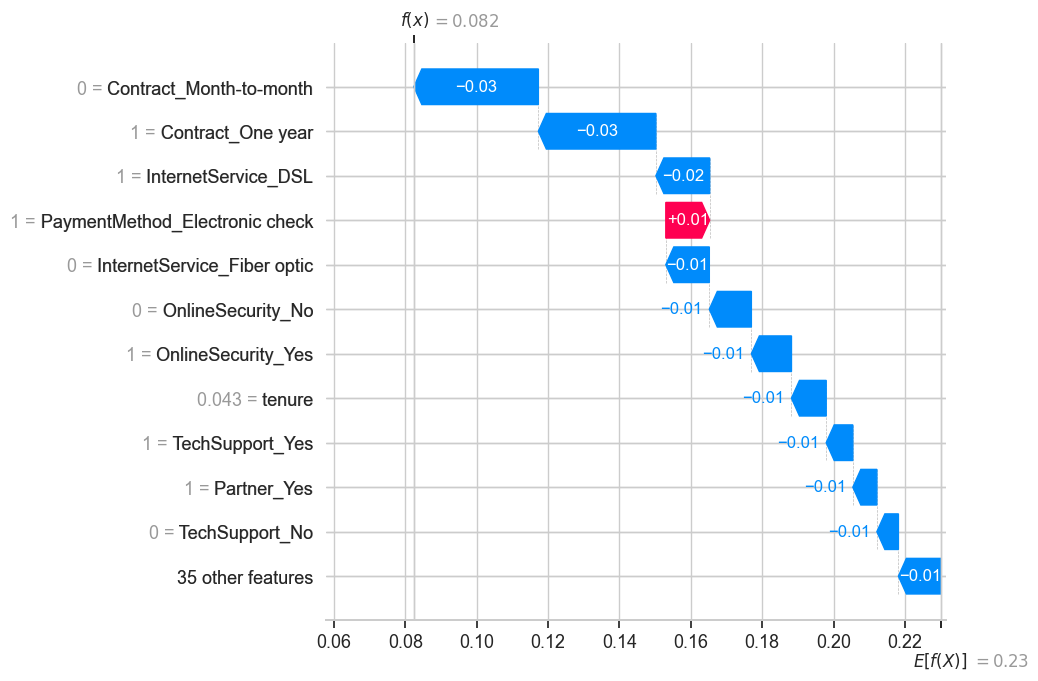

In [78]:
# Valores SHAP de los dos clientes

shap_clientes = explainer(
    X_clientes,
    max_evals=2 * X_clientes.shape[1] + 1
)

# Cliente predicho como Churn
shap.plots.waterfall(
    shap_clientes[0],
    max_display=12
)

# Cliente predicho como No Churn
shap.plots.waterfall(
    shap_clientes[1],
    max_display=12
)


## Explicador LIME

In [79]:
# Crear explicador LIME

cat_indices = [
    i for i, nombre in enumerate(feature_names_final)
    if nombre not in num_cols
]

lime_explainer = LimeTabularExplainer(
    training_data=X_train_final_prep.to_numpy(),
    feature_names=list(feature_names_final),
    class_names=["No Churn", "Churn"],
    categorical_features=cat_indices,
    mode="classification",
    discretize_continuous=True,
    random_state=SEED
)

print("Explicador LIME creado correctamente")


Explicador LIME creado correctamente


In [80]:
# Explicar cliente predicho como Churn

exp_churn = lime_explainer.explain_instance(
    data_row=X_test_final_prep.iloc[idx_churn].to_numpy(),
    predict_fn=svc_final.predict_proba,
    num_features=10,
    num_samples=1000,
    labels=(1,)
)

# Mostrar explicacion
exp_churn.show_in_notebook(show_table=True)


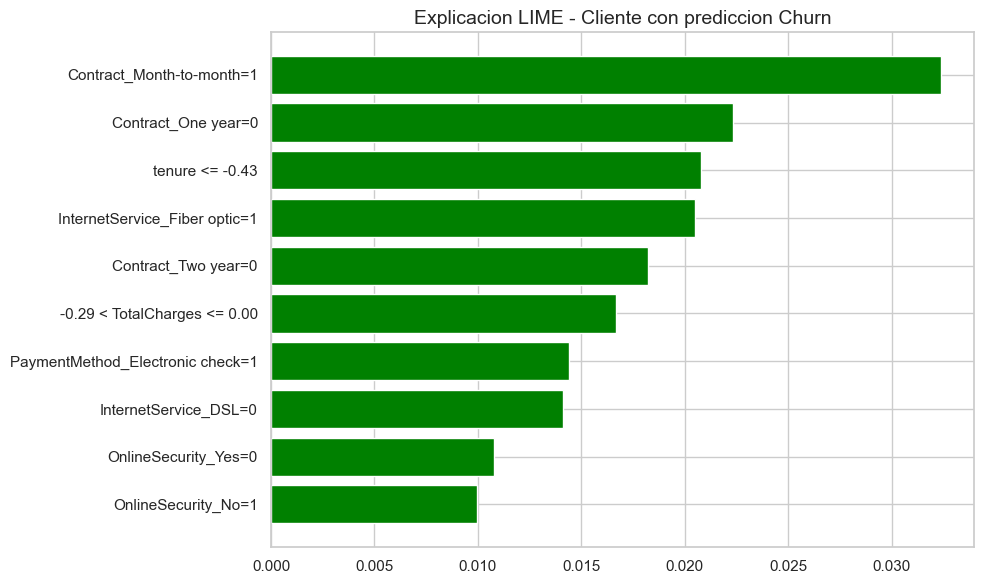

In [81]:

# Grafico LIME - Cliente Churn

fig = exp_churn.as_pyplot_figure(label=1)

fig.set_size_inches(10, 6)

plt.title(
    "Explicacion LIME - Cliente con prediccion Churn",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [82]:
# Explicar cliente predicho como No Churn

exp_no_churn = lime_explainer.explain_instance(
    data_row=X_test_final_prep.iloc[idx_no_churn].to_numpy(),
    predict_fn=svc_final.predict_proba,
    num_features=10,
    num_samples=1000,
    labels=(1,)
)

# Mostrar explicacion
exp_no_churn.show_in_notebook(show_table=True)


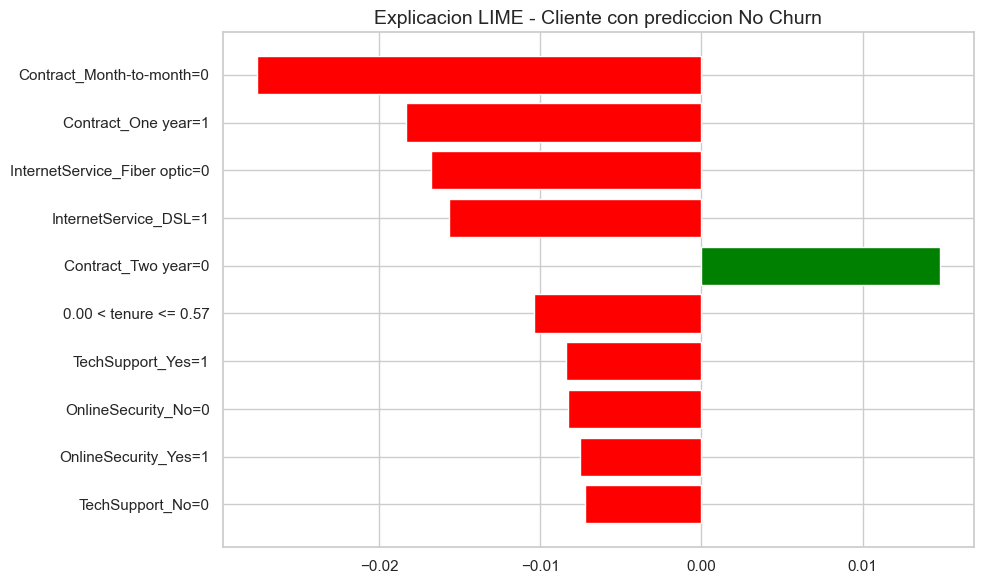

In [83]:
# Grafico LIME - Cliente No Churn

fig = exp_no_churn.as_pyplot_figure(label=1)

fig.set_size_inches(10, 6)

plt.title(
    "Explicacion LIME - Cliente con prediccion No Churn",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [84]:
# Comparacion de predicciones individuales

clientes_comparacion = X_test.iloc[
    [idx_churn, idx_no_churn]
]

probabilidades = final_model.predict_proba(
    clientes_comparacion
)[:, 1]

predicciones_clientes = final_model.predict(
    clientes_comparacion
)

tabla_clientes = pd.DataFrame({
    "Cliente": ["Cliente 1", "Cliente 2"],
    "Prediccion": predicciones_clientes,
    "Probabilidad Churn": probabilidades
})

display(tabla_clientes.round(4))


,Cliente,Prediccion,Probabilidad Churn
0,Cliente 1,1,0.5091
1,Cliente 2,0,0.0824


# COMPARACION

In [85]:
from sklearn.ensemble import RandomForestClassifier


# Modelo Random Forest de referencia

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=SEED,
    n_jobs=N_JOBS
)

# Entrenar con los datos preprocesados
rf_model.fit(X_train_final_prep, y_train_final)

print("Random Forest entrenado correctamente")


Random Forest entrenado correctamente


In [86]:

# Calcular importancia de caracteristicas

importancias_rf = rf_model.feature_importances_

# Crear DataFrame
df_importancias = pd.DataFrame({
    "Caracteristica": feature_names_final,
    "Importancia": importancias_rf
})

# Ordenar de mayor a menor
df_importancias = df_importancias.sort_values(
    by="Importancia",
    ascending=False
)

# Mostrar las 15 mas importantes
display(df_importancias.head(15))


,Caracteristica,Importancia
2,TotalCharges,0.152769
0,tenure,0.140797
1,MonthlyCharges,0.134365
37,Contract_Month-to-month,0.054007
19,OnlineSecurity_No,0.033694
44,PaymentMethod_Electronic check,0.031498
28,TechSupport_No,0.023060
17,InternetService_Fiber optic,0.022508
22,OnlineBackup_No,0.021006
39,Contract_Two year,0.019209


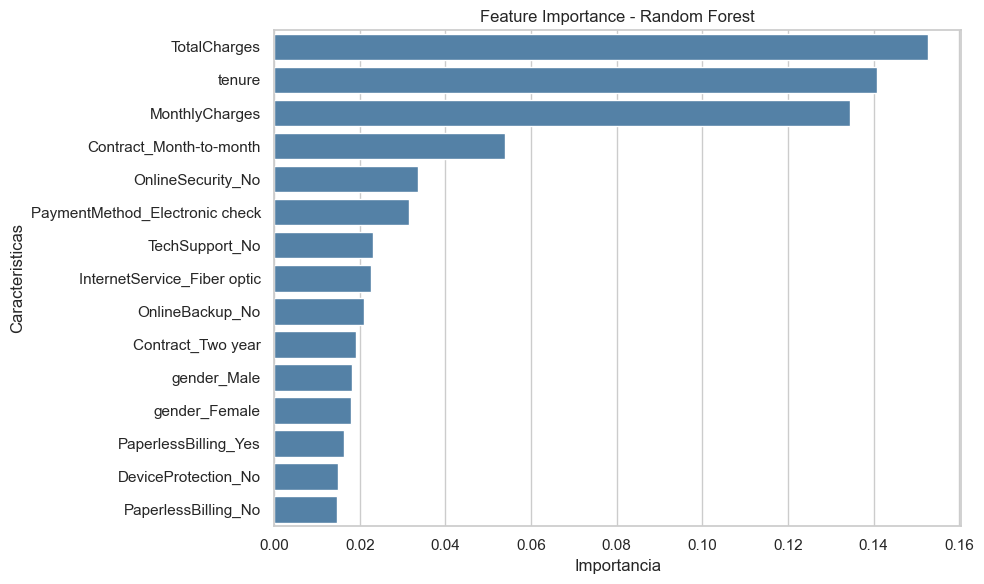

In [87]:

# Grafico de Feature Importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_importancias.head(15),
    x="Importancia",
    y="Caracteristica",
    color="steelblue"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Caracteristicas")
plt.tight_layout()
plt.show()


In [88]:

# Importancia global SHAP

importancias_shap = np.abs(
    shap_values.values
).mean(axis=0)

df_shap = pd.DataFrame({
    "Caracteristica": feature_names_final,
    "SHAP": importancias_shap
})

# Comparar con Random Forest
comparacion_xai = pd.merge(
    df_shap,
    df_importancias,
    on="Caracteristica"
)

comparacion_xai = comparacion_xai.rename(
    columns={"Importancia": "Random Forest"}
)

# Ordenar segun SHAP
comparacion_xai = comparacion_xai.sort_values(
    by="SHAP",
    ascending=False
)

display(comparacion_xai.head(15).round(4))



,Caracteristica,SHAP,Random Forest
37,Contract_Month-to-month,0.0350,0.0540
0,tenure,0.0227,0.1408
2,TotalCharges,0.0200,0.1528
17,InternetService_Fiber optic,0.0150,0.0225
38,Contract_One year,0.0147,0.0116
16,InternetService_DSL,0.0114,0.0118
39,Contract_Two year,0.0112,0.0192
19,OnlineSecurity_No,0.0091,0.0337
1,MonthlyCharges,0.0082,0.1344
28,TechSupport_No,0.0078,0.0231


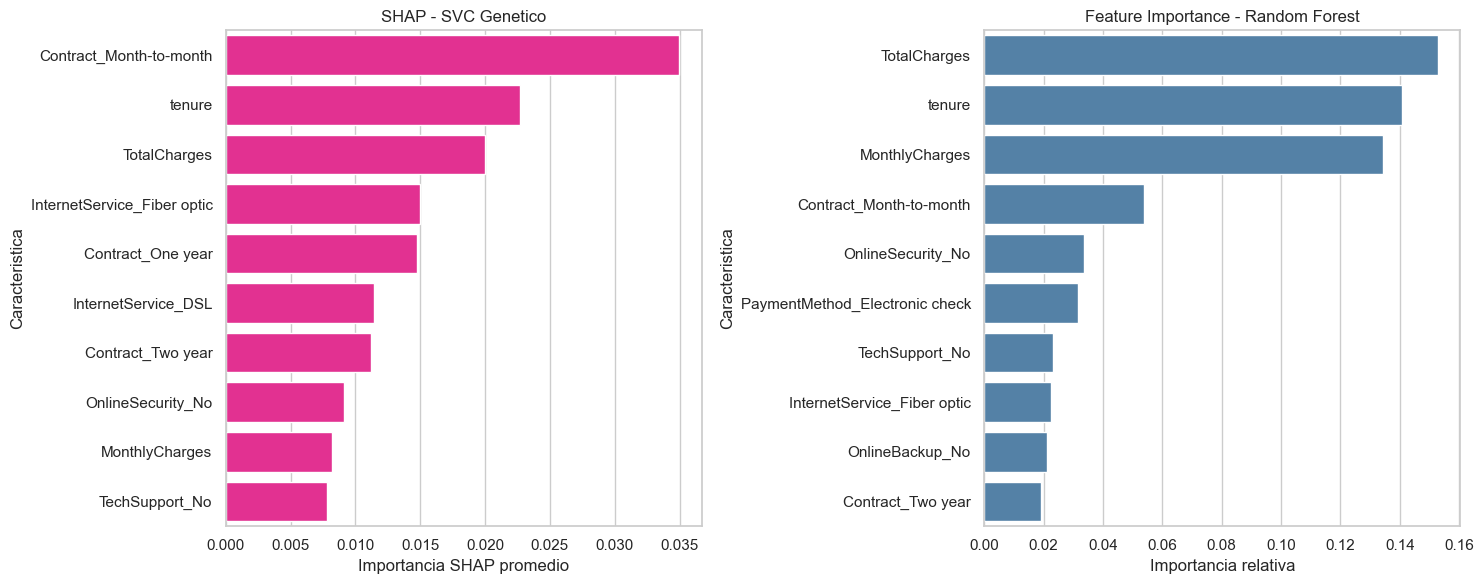

In [89]:

# Graficos comparativos

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# SHAP
top_shap = comparacion_xai.nlargest(10, "SHAP")

sns.barplot(
    data=top_shap,
    x="SHAP",
    y="Caracteristica",
    color="deeppink",
    ax=axes[0]
)

axes[0].set_title("SHAP - SVC Genetico")
axes[0].set_xlabel("Importancia SHAP promedio")

# Random Forest
top_rf = comparacion_xai.nlargest(10, "Random Forest")

sns.barplot(
    data=top_rf,
    x="Random Forest",
    y="Caracteristica",
    color="steelblue",
    ax=axes[1]
)

axes[1].set_title("Feature Importance - Random Forest")
axes[1].set_xlabel("Importancia relativa")

plt.tight_layout()
plt.show()


In [90]:
import sklearn
import sys

print("Scikit-learn:", sklearn.__version__)
print("Python:", sys.version)
print("Ejecutable:", sys.executable)


Scikit-learn: 1.7.2
Python: 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]
Ejecutable: c:\Users\diasj\OneDrive\Documentos\INTRODUCCION_A_LA_PROGRAMACION\.venv\Scripts\python.exe
